## Part 1: CNN


In [1]:
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

In [2]:
from pathlib import Path
import torch

base_dir = Path('workshops/7/Cats_and_Dogs')
train = base_dir / 'train'
val = base_dir / 'val'
test = base_dir / 'test'

img_width, img_height, channels = 150, 150, 3
input_shape = (3, img_height, img_width)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

batch_size = 32


Using device: cuda


In [3]:
# Define transforms for data preprocessing
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
    'val': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
    'test': transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
        transforms.Normalize(imagenet_mean, imagenet_std),
    ]),
}

train_dataset = datasets.ImageFolder(train, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test, transform=data_transforms['test'])

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2,
                          pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2,
                        pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2,
                         pin_memory=True, persistent_workers=True)

In [4]:
# Define CNN model
import torch.nn as nn


class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 18 * 18, 64)
        self.relu4 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu4(self.fc1(x)))
        return self.fc2(x)


model = CNNModel().to(device)
print(model)

CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=20736, out_features=64, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)


In [5]:
# Define loss function and optimizer
# Binary Cross Entropy with Logits (combines Sigmoid and BCE for better numerical stability)
# Note: If using BCEWithLogitsLoss, remove sigmoid from model's last layer
criterion = nn.BCEWithLogitsLoss()
# Alternatively: use nn.BCELoss() if you keep sigmoid in the model

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [6]:
    # Training loop for PyTorch

# you can try different number of epochs: 10, 15, 20; check the learning curves, loss and accuracy;
num_epochs = 10

# Lists to store training history
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

# Main training loop
for epoch in range(num_epochs):
    # Training phase
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)  # Reshape for binary classification

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation phase
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            labels = labels.float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_acc = 100 * val_correct / val_total
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f'Epoch [{epoch + 1}/{num_epochs}], '
          f'Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

Epoch [1/10], Train Loss: 0.5981, Train Acc: 66.61%, Val Loss: 0.5002, Val Acc: 75.10%


Epoch [2/10], Train Loss: 0.4861, Train Acc: 77.02%, Val Loss: 0.4506, Val Acc: 78.59%


Epoch [3/10], Train Loss: 0.4217, Train Acc: 80.89%, Val Loss: 0.4271, Val Acc: 79.96%


Epoch [4/10], Train Loss: 0.3702, Train Acc: 84.03%, Val Loss: 0.3879, Val Acc: 81.97%


Epoch [5/10], Train Loss: 0.3221, Train Acc: 86.18%, Val Loss: 0.3920, Val Acc: 83.05%


Epoch [6/10], Train Loss: 0.2720, Train Acc: 88.53%, Val Loss: 0.4436, Val Acc: 82.05%


Epoch [7/10], Train Loss: 0.2305, Train Acc: 90.38%, Val Loss: 0.3963, Val Acc: 84.14%


Epoch [8/10], Train Loss: 0.1896, Train Acc: 92.03%, Val Loss: 0.4089, Val Acc: 84.18%


Epoch [9/10], Train Loss: 0.1646, Train Acc: 93.23%, Val Loss: 0.4021, Val Acc: 83.78%


Epoch [10/10], Train Loss: 0.1409, Train Acc: 94.24%, Val Loss: 0.4349, Val Acc: 85.06%


In [7]:
# Evaluate on test data
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)

        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_accuracy = 100 * test_correct / test_total
print(f"Accuracy on test data: {test_accuracy:.2f}%")

Accuracy on test data: 84.52%


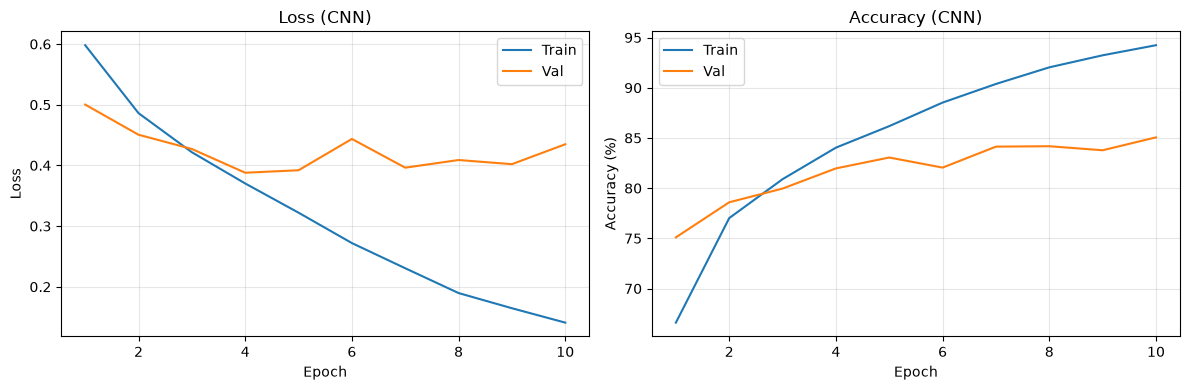

In [8]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, train_losses, label='Train')
ax1.plot(epochs, val_losses, label='Val')
ax1.set_title('Loss (CNN)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs, train_accuracies, label='Train')
ax2.plot(epochs, val_accuracies, label='Val')
ax2.set_title('Accuracy (CNN)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Part 2: Transfer Learning


In [9]:
# First, download the weights of the VGG16 network trained on the ImageNet dataset:
# PyTorch will automatically download the weights when you first run this

vgg16_net = models.vgg16(pretrained=True)  # Load pre-trained VGG16
# Remove the classifier (fully connected layers) - we take only the "convolution" part
vgg16_net = vgg16_net.features  # Extract only convolutional features

# Freeze the weights - we do NOT want to retrain the VGG16 layers
# Weights VGG16 in the process of learning will remain unchanged!
for param in vgg16_net.parameters():
    param.requires_grad = False

print(vgg16_net)  # pay attention to the architecture

C:\Users\Nikita\projects\2026-MLT\venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
C:\Users\Nikita\projects\2026-MLT\venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU(inplace=True)
  (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU(inplace=True)
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU(inplace=True)
  (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU(inplace=True)
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): ReLU(inplace=True)
  (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (13): ReLU(inplace=True)
  (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (15): ReLU(inplace=True)
  (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (17): Conv2d(256, 512, kernel_si

In [10]:
# Build transfer learning model by adding fully connected layers to VGG16

class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features  # Pre-trained VGG16 features

        # Adaptive pooling to handle feature input sizes
        # That operation shrinks the feature map size to 7x7
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        # Flattening (done in forward)
        # Dense fully connected layer with 256 neurons
        self.fc1 = nn.Linear(512 * 7 * 7, 256)  # VGG16 outputs 512 channels
        self.relu = nn.ReLU()

        # Dropout
        self.dropout = nn.Dropout(0.5)

        # Dense layer with 1 neuron (no sigmoid if using BCEWithLogitsLoss)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)  # Flatten

        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model = VGG16TransferModel(vgg16_net).to(device)
print(model)

VGG16TransferModel(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, paddin

In [11]:
# Define loss and optimizer for transfer learning model
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-5)  # Lower learning rate 1e-5 for fine-tuning

In [12]:
num_epochs_transfer = 5

train_losses_transfer = []
train_accuracies_transfer = []
val_losses_transfer = []
val_accuracies_transfer = []

for epoch in range(num_epochs_transfer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    train_losses_transfer.append(running_loss / len(train_loader))
    train_accuracies_transfer.append(100 * correct / total)

    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_losses_transfer.append(val_running_loss / len(val_loader))
    val_accuracies_transfer.append(100 * val_correct / val_total)

    print(f'Epoch [{epoch + 1}/{num_epochs_transfer}], '
          f'Train Loss: {train_losses_transfer[-1]:.4f}, Train Acc: {train_accuracies_transfer[-1]:.2f}%, '
          f'Val Loss: {val_losses_transfer[-1]:.4f}, Val Acc: {val_accuracies_transfer[-1]:.2f}%')

vgg16_history = {
    'train_losses': train_losses_transfer,
    'train_accuracies': train_accuracies_transfer,
    'val_losses': val_losses_transfer,
    'val_accuracies': val_accuracies_transfer,
}

Epoch [1/5], Train Loss: 0.0814, Train Acc: 97.00%, Val Loss: 0.0680, Val Acc: 97.31%


Epoch [2/5], Train Loss: 0.0456, Train Acc: 98.36%, Val Loss: 0.0482, Val Acc: 98.31%


Epoch [3/5], Train Loss: 0.0341, Train Acc: 98.74%, Val Loss: 0.0553, Val Acc: 98.15%


Epoch [4/5], Train Loss: 0.0275, Train Acc: 99.05%, Val Loss: 0.0495, Val Acc: 98.39%


Epoch [5/5], Train Loss: 0.0223, Train Acc: 99.27%, Val Loss: 0.0486, Val Acc: 98.43%


In [13]:
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)
        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

vgg16_test_acc = 100 * test_correct / test_total
vgg16_model = model
print(f"VGG16 accuracy on test data: {vgg16_test_acc:.2f}%")

VGG16 accuracy on test data: 97.60%


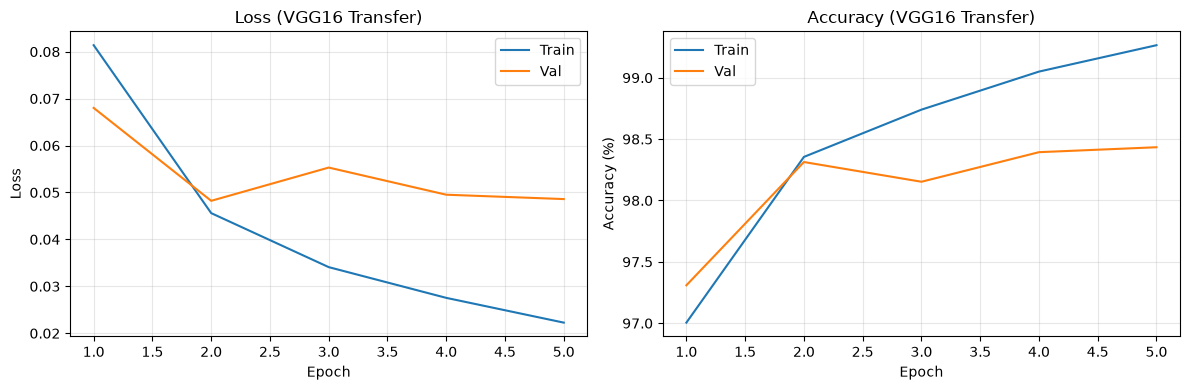

In [14]:
epochs = range(1, len(train_losses_transfer) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, train_losses_transfer, label='Train')
ax1.plot(epochs, val_losses_transfer, label='Val')
ax1.set_title('Loss (VGG16 Transfer)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs, train_accuracies_transfer, label='Train')
ax2.plot(epochs, val_accuracies_transfer, label='Val')
ax2.set_title('Accuracy (VGG16 Transfer)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### ResNet18


In [15]:
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for param in resnet.parameters():
    param.requires_grad = False
resnet.fc = nn.Sequential(
    nn.Linear(resnet.fc.in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 1)
)

model = resnet.to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-4)

num_epochs_transfer = 5
train_losses_resnet, train_accuracies_resnet = [], []
val_losses_resnet, val_accuracies_resnet = [], []

for epoch in range(num_epochs_transfer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    train_losses_resnet.append(running_loss / len(train_loader))
    train_accuracies_resnet.append(100 * correct / total)

    model.eval()
    val_running_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item()
            predicted = (torch.sigmoid(outputs) > 0.5).float()
            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()
    val_losses_resnet.append(val_running_loss / len(val_loader))
    val_accuracies_resnet.append(100 * val_correct / val_total)

    print(f'Epoch [{epoch + 1}/{num_epochs_transfer}], '
          f'Train Loss: {train_losses_resnet[-1]:.4f}, Train Acc: {train_accuracies_resnet[-1]:.2f}%, '
          f'Val Loss: {val_losses_resnet[-1]:.4f}, Val Acc: {val_accuracies_resnet[-1]:.2f}%')

resnet_history = {
    'train_losses': train_losses_resnet,
    'train_accuracies': train_accuracies_resnet,
    'val_losses': val_losses_resnet,
    'val_accuracies': val_accuracies_resnet,
}


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Nikita/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


0.3%

0.6%

0.8%

1.1%

1.4%

... (354 outputs left out)

Epoch [2/5], Train Loss: 0.1622, Train Acc: 92.97%, Val Loss: 0.1170, Val Acc: 95.30%


Epoch [3/5], Train Loss: 0.1540, Train Acc: 93.55%, Val Loss: 0.1105, Val Acc: 95.46%


Epoch [4/5], Train Loss: 0.1474, Train Acc: 93.67%, Val Loss: 0.1173, Val Acc: 94.90%


Epoch [5/5], Train Loss: 0.1422, Train Acc: 94.00%, Val Loss: 0.1157, Val Acc: 95.06%


ResNet18 accuracy on test data: 94.88%


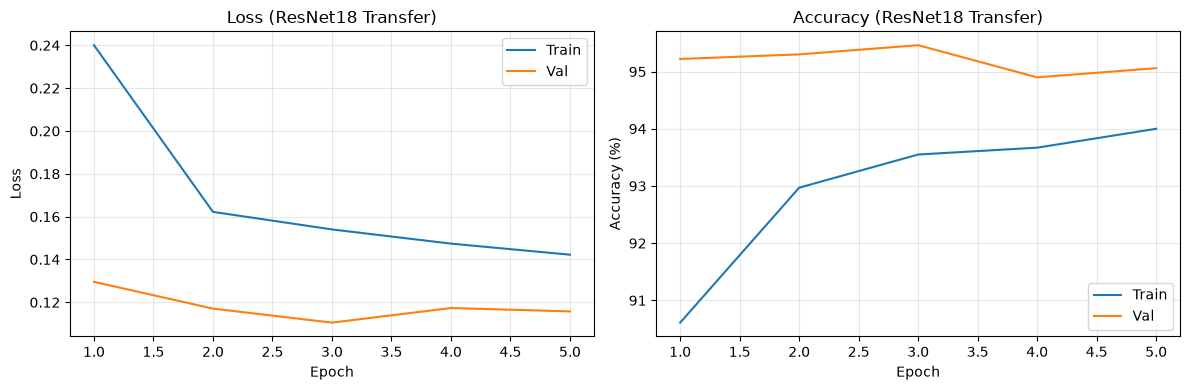

,Test Accuracy (%)
Model,
VGG16 Transfer,97.60
ResNet18 Transfer,94.88


In [16]:
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        labels = labels.float().unsqueeze(1)
        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

resnet_test_acc = 100 * test_correct / test_total
resnet_model = model
print(f"ResNet18 accuracy on test data: {resnet_test_acc:.2f}%")

epochs = range(1, len(resnet_history['train_losses']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, resnet_history['train_losses'], label='Train')
ax1.plot(epochs, resnet_history['val_losses'], label='Val')
ax1.set_title('Loss (ResNet18 Transfer)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs, resnet_history['train_accuracies'], label='Train')
ax2.plot(epochs, resnet_history['val_accuracies'], label='Val')
ax2.set_title('Accuracy (ResNet18 Transfer)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

import pandas as pd

comparison_df = pd.DataFrame([
    {'Model': 'VGG16 Transfer', 'Test Accuracy (%)': round(vgg16_test_acc, 2)},
    {'Model': 'ResNet18 Transfer', 'Test Accuracy (%)': round(resnet_test_acc, 2)},
]).set_index('Model')
comparison_df


## Inference


In [17]:
from PIL import Image


def predict_image(image_path, model, device):
    class_names = train_dataset.classes
    image = Image.open(image_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize((img_width, img_height)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    x = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(x)).item()

    label_idx = int(prob > 0.5)
    confidence = prob if label_idx == 1 else 1 - prob
    return class_names[label_idx], confidence


best_model, best_name = (vgg16_model, 'VGG16') if vgg16_test_acc >= resnet_test_acc else (resnet_model, 'ResNet18')
print(f"Best model: {best_name}")

Best model: VGG16
